# Proyecto Integrador — Avance 5
## Evaluación de ensambles heterogéneos para reconstrucción de tiempos de viaje

**Equipo 42 · Resultados experimentales documentados**

**Objetivo.** Determinar si combinar modelos de distintas familias mejora la reconstrucción de los tiempos de **345 aristas** y las matrices origen–destino (OD), utilizando **32 consultas guía** frente al modelo individual Ridge del Avance 4.

**Alcance.** Se presentan ensambles por *blending* y una primera variante de *stacking*, con comparación de precisión, errores individuales, subestimaciones y una exploración de incertidumbre. Las observaciones actuales provienen de una simulación retrospectiva sobre PEMS-BAY; no constituyen consultas reales a un proveedor de tráfico.

**Lectura rápida:** en mayo, el blending **75% Ridge + 25% KNN** obtuvo **MAE OD 11.2710 s**, frente a **11.5116 s** de Ridge, una reducción de **2.09%**. Es una mejora pequeña y no concluyente en el análisis exploratorio de incertidumbre.

## 1. Diseño experimental y criterios

El enfoque conserva el mismo problema del Avance 4: **32 desviaciones relativas de tiempos OD** como entrada y **345 desviaciones relativas de aristas** como objetivo. Con los tiempos reconstruidos se utiliza **Dijkstra** para obtener matrices OD. La selección de las 32 consultas se reproduce con el criterio *greedy* original calculado sobre enero–marzo.

**División temporal:**

| Uso | Entrenamiento de modelos base | Periodo evaluado | Finalidad |
|---|---|---|---|
| Exploración de pesos | Enero–marzo | Abril (120 instantes) | Probar combinaciones |
| Comprobación del candidato | Enero–abril | Mayo (120 instantes) | Comparación posterior del peso 75/25 |
| Prueba del metamodelo de stacking | Predicciones de abril, con bases entrenadas hasta marzo | Mayo, bases reentrenadas hasta abril | Evaluación exploratoria |

**Criterio principal:** MAE de tiempos OD en segundos. Se incluyen RMSE, WAPE, P95 y errores de subestimación. Se emplean **dos grupos de 20 nodos**, equivalentes a 760 OD dirigidos por instante y **91,200 predicciones** en 120 instantes. El código fija una selección reproducible de nodos mediante semilla 42; **debe comprobarse su identidad con los grupos exactos del Avance 4 antes de afirmar equivalencia estricta**.

**Límite de independencia:** abril se utiliza para seleccionar pesos; mayo se consultó repetidamente durante la exploración, por lo que los análisis de mayo no deben presentarse como una validación inédita de todo el proceso. Junio ya había sido consultado en el Avance 4. No se realizó una nueva prueba final independiente.

## 2. Preparación del entorno y lectura de archivos

Se monta Google Drive y se recupera `routing_dataset_v1`. Se verifican **322 nodos, 345 aristas y 52,116 instantes históricos**. El código utiliza la carpeta de proyecto existente; no genera ni modifica mediciones de PEMS-BAY.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

raiz = Path('/content/drive/MyDrive')

archivos = list(raiz.rglob('edge_travel_times.parquet'))

for archivo in archivos:
    print(archivo)

/content/drive/MyDrive/Maestría en Inteligencia Artificial Aplicada/Proyecto Integrador/routing_dataset_v1/edge_travel_times.parquet


In [ ]:
%pip -q install pyarrow

import pandas as pd

ruta_datos = archivos[0].parent

nodes = pd.read_csv(ruta_datos / 'nodes.csv')
edges = pd.read_csv(ruta_datos / 'edges.csv')
tiempos = pd.read_parquet(ruta_datos / 'edge_travel_times.parquet')

print("Nodos:", nodes.shape)
print("Aristas:", edges.shape)
print("Tiempos:", tiempos.shape)

Nodos: (322, 6)
Aristas: (345, 12)
Tiempos: (52116, 345)


## 3. Recuperación de las consultas guía y las variables del Avance 4

El notebook original se lee como fuente de procedimientos ya definidos. Después se ejecutan sus celdas de preparación y selección para recuperar el orden original de consultas; las primeras **32 de 64** se guardan en `consultas_k32_avance4.json`. El procesamiento usa sólo enero–marzo para seleccionar las consultas. **Este paso puede construir archivos derivados OD en Drive si no existen**, pero no altera el notebook Avance 4.

**Nota de reproducibilidad:** la siguiente celda de lectura del Avance 4 conserva una salida de diagnóstico extensa de la ejecución original. Las celdas auxiliares de búsqueda que no aportaban al flujo fueron retiradas.

In [ ]:
import json
from pathlib import Path

# Carpeta principal del proyecto
carpeta_proyecto = Path(
    "/content/drive/MyDrive/Maestría en Inteligencia Artificial Aplicada/Proyecto Integrador"
)

# Notebook del Avance 4
ruta_avance4 = carpeta_proyecto / "Avance4_42.ipynb"

with open(ruta_avance4, "r", encoding="utf-8") as f:
    nb4 = json.load(f)

print("Avance 4 cargado correctamente")
print("Número de celdas:", len(nb4["cells"]))

# Identificar el código que define las consultas guía
for i, celda in enumerate(nb4["cells"]):
    contenido = "".join(celda.get("source", []))

    if celda["cell_type"] == "code" and any(
        palabra in contenido.lower()
        for palabra in ["selected_queries", "guide_queries", "greedy", "selected_od"]
    ):
        print(f"\n{'='*50}")
        print(f"CELDA {i}")
        print(contenido[:3000])

Avance 4 cargado correctamente
Número de celdas: 63

CELDA 18

# ------------------------------------------------------------
# 6.1 Selección progresiva de consultas OD
# ------------------------------------------------------------

# Correlaciones calculadas exclusivamente con enero-marzo
r2_matrix = np.square(
    od_edge_corr.astype(np.float64)
)

assert r2_matrix.shape == (
    len(valid_od_columns),
    340
)

MAX_QUERIES = 64

available = np.ones(
    len(valid_od_columns),
    dtype=bool
)

coverage = np.zeros(
    len(valid_edges),
    dtype=float
)

selected_indices = []
selection_records = []

# ------------------------------------------------------------
# Selección greedy
# ------------------------------------------------------------

for step in range(MAX_QUERIES):

    # Cobertura que proporcionaría cada consulta
    new_coverage = np.maximum(
        coverage[None, :],
        r2_matrix
    )

    gains = (
        new_coverage.mean(axis=1)
        - coverage.mean()
    

In [ ]:
import os
import numpy as np

# Utilizar la misma carpeta de datos que ya cargamos
os.environ["ROUTE_INTELLIGENCE_DATASET_DIR"] = str(ruta_datos)

# Ejecutar las dependencias originales del Avance 4
# sin modificar el archivo Avance4_42.ipynb
for numero_celda in [4, 6, 9, 15, 18]:
    print(f"\nEjecutando celda original {numero_celda}...")

    codigo = "".join(nb4["cells"][numero_celda]["source"])
    exec(compile(codigo, f"Avance4_celda_{numero_celda}", "exec"))

# Recuperar las primeras 32 consultas
consultas_k32 = valid_od_columns[selected_indices[:32]].tolist()

assert len(consultas_k32) == 32
assert len(set(consultas_k32)) == 32

print("\n32 consultas recuperadas:")
for i, consulta in enumerate(consultas_k32, start=1):
    print(f"{i:2d}. {consulta}")

# Guardar la selección para no volver a calcularla
import json

ruta_consultas = carpeta_proyecto / "consultas_k32_avance4.json"

with open(ruta_consultas, "w", encoding="utf-8") as f:
    json.dump(consultas_k32, f, indent=2)

print("\nSelección guardada en:", ruta_consultas)


Ejecutando celda original 4...
Dataset base recuperado: /content/drive/MyDrive/Maestría en Inteligencia Artificial Aplicada/Proyecto Integrador/routing_dataset_v1
Nodos: 322 | Aristas: 345
Serie temporal: (52116, 345)
Periodo: 2017-01-01 00:00:00 → 2017-06-30 23:55:00
Entrenamiento inicial: (25908, 345)
Validación preliminar: (8640, 345)
Tipos de arista:
edge_type
corridor                 273
sensor_to_interchange     36
interchange_to_sensor     36
Name: count, dtype: int64
Tiempos mínimo y máximo (min): 0.00811 31.56923

Ejecutando celda original 6...
Caracterización residual completada.

Grupos históricos: 2016
Aristas analizadas: 345

Resumen por tipo de arista:


,edge_type,aristas,mediana_desv_rel_abril_pct,mediana_mae_abril_s
0,corridor,273,1.414,1.180
1,interchange_to_sensor,36,1.496,0.910
2,sensor_to_interchange,36,1.254,0.304



12 aristas con mayor desviación relativa en entrenamiento:


,edge_id,corridor,edge_type,mediana_desv_rel_ent_pct,mediana_desv_rel_abril_pct,mae_abril_s
289,E289,880-N,sensor_to_interchange,5.843,7.473,0.293
277,E277,237-W,sensor_to_interchange,4.659,5.637,0.887
227,E227,87-S,corridor,4.443,4.321,2.347
58,E058,237-E,corridor,4.293,4.586,4.301
59,E059,237-E,corridor,4.129,4.299,9.096
333,E333,101-S,sensor_to_interchange,3.846,2.183,2.021
310,E310,237-W,interchange_to_sensor,3.642,2.314,1.828
319,E319,85-S,sensor_to_interchange,3.640,5.224,0.117
228,E228,87-S,corridor,3.594,3.695,0.645
0,E000,101-N,corridor,3.516,3.233,0.363



MAE global K=0, abril: 1.538 s
Mediana global de desviación relativa absoluta: 1.462%

Ejecutando celda original 9...
Aristas originales: 345
Aristas con variación: 340
Series excluidas por variación casi nula: 5

Estructura de correlación histórica:


,Tipo,Pares,Mediana |corr|,P90 |corr|,Fracción |corr| >= 0.7 (%),Fracción |corr| >= 0.9 (%)
0,Todos los pares,57630,0.083,0.221,0.595,0.127
1,Mismo corredor,4281,0.168,0.630,8.012,1.705
2,Corredores diferentes,53349,0.079,0.203,0.000,0.000


... (5 outputs left out)

,aristas,mediana_max_corr,minimo_max_corr
corridor,,,
237-E,8,0.510,0.420
237-W,12,0.583,0.326
87-N,25,0.586,0.262
101-S,32,0.613,0.309
880-N,20,0.618,0.427
680-S,14,0.640,0.378
85-N,39,0.641,0.409
880-S,24,0.650,0.249
87-S,22,0.658,0.143



Análisis realizado exclusivamente con enero-marzo.
No se han seleccionado consultas ni modelos.

Ejecutando celda original 18...
Selección progresiva completada.

Consultas ordenadas: 64

Primeras 20 consultas:


,Orden,Consulta OD,Ganancia marginal,Cobertura media R2
0,1,I08__I05,0.07652,0.07652
1,2,I10__I08,0.04072,0.11723
2,3,I09__I10,0.01864,0.13587
3,4,I11__I10,0.01737,0.15325
4,5,I11__I07,0.01603,0.16928
5,6,I12__I01,0.01539,0.18467
6,7,I01__I05,0.01513,0.19981
7,8,I01__I12,0.01377,0.21358
8,9,I02__I03,0.01357,0.22715
9,10,I07__I09,0.01203,0.23918



Selección basada exclusivamente en entrenamiento.

32 consultas recuperadas:
 1. I08__I05
 2. I10__I08
 3. I09__I10
 4. I11__I10
 5. I11__I07
 6. I12__I01
 7. I01__I05
 8. I01__I12
 9. I02__I03
10. I07__I09
11. I02__I06
12. I07__I00
13. I01__I02
14. I00__I07
15. I04__I03
16. I02__I01
17. I05__I01
18. I12__I03
19. I03__I04
20. I06__I00
21. I06__I02
22. I04__I10
23. I09__I07
24. I03__I12
25. I10__I12
26. I02__I11
27. I03__I02
28. I12__I10
29. I00__I11
30. I12__I11
31. I04__I09
32. I08__I07

Selección guardada en: /content/drive/MyDrive/Maestría en Inteligencia Artificial Aplicada/Proyecto Integrador/consultas_k32_avance4.json


### 3.1. Preparación de X e Y

Se aprovecha el código original del Avance 4 para construir las desviaciones relativas. **X** representa las consultas OD candidatas, de las cuales se toman las 32 seleccionadas; **Y** representa las desviaciones de las 345 aristas.

Se esperan **25,908 instantes × 32 consultas** y **25,908 × 345 objetivos** para enero–marzo.

In [ ]:
# ------------------------------------------------------------
# Recuperar la preparación de datos del Avance 4
# ------------------------------------------------------------

codigo = "".join(nb4["cells"][19]["source"])

# Ejecutar solamente la parte que construye X e Y,
# sin repetir los experimentos posteriores.
codigo_preparacion = codigo.split(
    "# ------------------------------------------------------------\n"
    "# Tamaños exploratorios"
)[0]

exec(compile(
    codigo_preparacion,
    "Avance4_preparacion_XY",
    "exec"
))

print("X_train_all:", X_train_all.shape)
print("Y_train_all:", Y_train_all.shape)
print("X_april_all:", X_april_all.shape)

X_train_all: (25908, 156)
Y_train_all: (25908, 345)
X_april_all: (8640, 156)


In [ ]:
# ------------------------------------------------------------
# Paso 4. Preparación de entradas y objetivos
# ------------------------------------------------------------

import numpy as np

# Recuperar las 32 posiciones originales
indices_k32 = selected_indices[:32]

# Entradas: desviaciones de las consultas OD
X_enero_marzo = X_train_all[:, indices_k32]

# Objetivos: desviaciones de las 345 aristas
Y_enero_marzo = Y_train_all

print("Entradas X:", X_enero_marzo.shape)
print("Objetivos Y:", Y_enero_marzo.shape)

assert X_enero_marzo.shape == (25908, 32)
assert Y_enero_marzo.shape == (25908, 345)

print("\nPreparación correcta.")

Entradas X: (25908, 32)
Objetivos Y: (25908, 345)

Preparación correcta.


## 4. Modelos individuales y primer blending: Ridge + KNN

Se entrenan modelos de familias distintas: **Ridge** (regresión lineal regularizada, `alpha=1000`) y **KNN** (15 vecinos ponderados por distancia). Ambos reciben las mismas 32 consultas y estiman las 345 aristas.

Se evalúan mezclas con pesos de Ridge de **0%, 25%, 50%, 75% y 100%**; el complemento corresponde a KNN. Se compara primero el MAE por arista y después el MAE de los viajes OD. Las tablas muestran que **la mejor mezcla por arista no coincide con la mejor mezcla por OD**.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from time import perf_counter

# Modelo Ridge
ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1000.0))
])

# Modelo KNN
knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor(
        n_neighbors=15,
        weights="distance",
        n_jobs=-1
    ))
])

# Entrenar ambos con enero-marzo
modelos = {"Ridge": ridge, "KNN": knn}

for nombre, modelo in modelos.items():
    inicio = perf_counter()
    modelo.fit(X_enero_marzo, Y_enero_marzo)
    duracion = perf_counter() - inicio

    print(f"{nombre}: entrenamiento completado en {duracion:.3f} segundos")

# Preparar observaciones de abril
X_validacion = X_april_all[:, indices_k32]

print("\nDatos de validación:", X_validacion.shape)

# Generar predicciones
pred_ridge = ridge.predict(X_validacion)
pred_knn = knn.predict(X_validacion)

print("Predicciones Ridge:", pred_ridge.shape)
print("Predicciones KNN:", pred_knn.shape)

Ridge: entrenamiento completado en 0.619 segundos
KNN: entrenamiento completado en 0.054 segundos

Datos de validación: (8640, 32)
Predicciones Ridge: (8640, 345)
Predicciones KNN: (8640, 345)


### 4.1. Comparación preliminar por arista — abril

La combinación 50/50 obtiene el menor **MAE por arista (1.2040 s)**. Este resultado no basta para seleccionar el ensamble: el objetivo principal son los tiempos de viaje OD completos.

In [ ]:
import numpy as np
import pandas as pd

# Evaluación inicial por arista sobre abril
# Todas las cantidades de tiempo están en minutos
pesos_ridge = [0.0, 0.25, 0.50, 0.75, 1.0]

resultados_blending = []

for peso in pesos_ridge:

    # Combinar desviaciones relativas estimadas
    pred_relativa = (
        peso * pred_ridge
        + (1 - peso) * pred_knn
    )

    # Convertir desviaciones a tiempos de viaje
    tiempos_predichos = expected_april * (
        1 + pred_relativa
    )

    # Respaldo histórico para tiempos no positivos
    tiempos_predichos = np.where(
        tiempos_predichos > 0,
        tiempos_predichos,
        expected_april
    )

    # Comparar contra los tiempos de referencia
    errores_segundos = 60 * (
        tiempos_predichos - actual_april
    )

    mae = np.mean(np.abs(errores_segundos))
    rmse = np.sqrt(
        np.mean(errores_segundos ** 2)
    )
    p95 = np.percentile(
        np.abs(errores_segundos), 95
    )

    resultados_blending.append({
        "Peso Ridge": peso,
        "Peso KNN": 1 - peso,
        "MAE aristas (s)": mae,
        "RMSE aristas (s)": rmse,
        "P95 aristas (s)": p95
    })

tabla_blending = pd.DataFrame(resultados_blending)

tabla_blending = tabla_blending.sort_values(
    "MAE aristas (s)"
).reset_index(drop=True)

display(tabla_blending.round(4))

,Peso Ridge,Peso KNN,MAE aristas (s),RMSE aristas (s),P95 aristas (s)
0,0.50,0.50,1.2040,5.4994,4.2578
1,0.75,0.25,1.2199,5.3939,4.3218
2,0.25,0.75,1.2404,5.7875,4.4073
3,1.00,0.00,1.2882,5.4895,4.5976
4,0.00,1.00,1.3321,6.2302,4.7658


### 4.2. Comparación por viaje OD — abril

Al reconstruir matrices OD con Dijkstra, el menor MAE corresponde a **75% Ridge + 25% KNN: 9.1325 s**; Ridge individual alcanza **9.4479 s**. La reducción aproximada es **3.34%**. El P95 de Ridge individual es ligeramente menor (37.5180 frente a 37.7823 s), de modo que no todas las métricas favorecen al ensamble.

In [ ]:
# ------------------------------------------------------------
# PASO 7. Evaluación OD de Ridge + KNN
# ------------------------------------------------------------

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from time import perf_counter

# 1. Recuperar los mismos grupos del Avance 4
node_ids = nodes["node_id"].astype(str).tolist()
node_to_idx = {node: i for i, node in enumerate(node_ids)}

sensor_nodes = sorted(
    nodes.loc[
        nodes["node_type"] != "interchange",
        "node_id"
    ].astype(str).tolist()
)

rng = np.random.default_rng(42)
chosen_nodes = rng.choice(sensor_nodes, size=40, replace=False)

target_idx = np.array([
    node_to_idx[n] for n in chosen_nodes
])

edge_from = edges["from"].astype(str).map(node_to_idx).to_numpy()
edge_to = edges["to"].astype(str).map(node_to_idx).to_numpy()

assert len(target_idx) == 40
assert np.isfinite(edge_from).all()
assert np.isfinite(edge_to).all()

# 2. Función para construir matrices OD mediante Dijkstra
def calcular_matriz_od(tiempos_aristas):
    grafo = csr_matrix(
        (tiempos_aristas, (edge_from, edge_to)),
        shape=(322, 322)
    )

    distancias = dijkstra(
        grafo,
        directed=True,
        indices=target_idx
    )

    return distancias[:, target_idx]

# 3. Utilizar los mismos 120 instantes de abril
posiciones = np.linspace(
    0, len(actual_april) - 1,
    num=120, dtype=int
)

referencia_od = np.stack([
    calcular_matriz_od(actual_april[i])
    for i in posiciones
])

baseline_aristas = expected_april[posiciones]

# 4. Evaluar las cinco combinaciones
resultados_od = []
mascara_od = ~np.eye(20, dtype=bool)

for peso_ridge in [0.0, 0.25, 0.50, 0.75, 1.0]:

    inicio = perf_counter()

    # Combinar predicciones relativas
    mezcla = (
        peso_ridge * pred_ridge[posiciones]
        + (1 - peso_ridge) * pred_knn[posiciones]
    )

    # Reconstruir tiempos por arista
    tiempos_raw = baseline_aristas * (1 + mezcla)

    no_positivos = 100 * np.mean(tiempos_raw <= 0)

    tiempos_validos = np.where(
        tiempos_raw > 0,
        tiempos_raw,
        baseline_aristas
    )

    # Calcular matrices OD
    matrices_estimadas = np.stack([
        calcular_matriz_od(fila)
        for fila in tiempos_validos
    ])

    errores = []
    referencias = []

    for inicio_grupo, fin_grupo in [(0, 20), (20, 40)]:

        reales = referencia_od[
            :, inicio_grupo:fin_grupo,
            inicio_grupo:fin_grupo
        ][:, mascara_od]

        estimados = matrices_estimadas[
            :, inicio_grupo:fin_grupo,
            inicio_grupo:fin_grupo
        ][:, mascara_od]

        errores.append(60 * (estimados - reales))
        referencias.append(reales)

    errores = np.concatenate([e.ravel() for e in errores])
    referencias = np.concatenate([r.ravel() for r in referencias])

    duracion = perf_counter() - inicio

    resultados_od.append({
        "Peso Ridge": peso_ridge,
        "Peso KNN": 1 - peso_ridge,
        "MAE OD (s)": np.mean(np.abs(errores)),
        "RMSE OD (s)": np.sqrt(np.mean(errores ** 2)),
        "WAPE (%)": 100 * np.sum(np.abs(errores))
                    / (60 * np.sum(referencias)),
        "P95 OD (s)": np.percentile(np.abs(errores), 95),
        "No positivos (%)": no_positivos,
        "Tiempo evaluación (s)": duracion
    })

tabla_od = pd.DataFrame(resultados_od)

tabla_od = tabla_od.sort_values(
    "MAE OD (s)"
).reset_index(drop=True)

display(tabla_od.round(4))

,Peso Ridge,Peso KNN,MAE OD (s),RMSE OD (s),WAPE (%),P95 OD (s),No positivos (%),Tiempo evaluación (s)
0,0.75,0.25,9.1325,24.7166,1.1935,37.7823,0.0024,0.3123
1,1.00,0.00,9.4479,24.7112,1.2347,37.5180,0.0169,0.2531
2,0.50,0.50,10.3824,27.4391,1.3568,47.2501,0.0000,0.3915
3,0.25,0.75,12.5516,32.2043,1.6403,60.2100,0.0000,0.4515
4,0.00,1.00,15.1819,37.9986,1.9840,75.6796,0.0000,0.2687


## 5. Verificación del blending seleccionado — mayo

Se mantiene **sin cambios el peso 75/25 elegido en abril**, se reentrenan Ridge y KNN con enero–abril y se comparan en mayo. Se obtiene **11.2710 s** de MAE OD para el blending frente a **11.5116 s** de Ridge y **18.5449 s** de KNN; la mejora frente a Ridge es **2.09%**. También disminuyen RMSE y P95.

Se prueba adicionalmente el peso **50/50** en mayo, sin reemplazar el candidato original: alcanza **12.7641 s**, un resultado inferior tanto al blending 75/25 como a Ridge. La consulta posterior a mayo de este peso es exploratoria, no una segunda selección independiente.

In [ ]:
# ------------------------------------------------------------
# PASO 8. Confirmación del blending en mayo de 2017
# ------------------------------------------------------------

import numpy as np
import pandas as pd
from sklearn.base import clone
from time import perf_counter

# 1. Recuperar la preparación original del Avance 4
codigo = "".join(nb4["cells"][26]["source"])
exec(compile(codigo, "Avance4_celda_26", "exec"))

# 2. Seleccionar 120 instantes distribuidos en mayo
pos_mayo = np.linspace(
    0, len(av4_edge_val) - 1,
    num=120, dtype=int
)

X_mayo = X_model_val[pos_mayo]
base_mayo = av4_edge_base_val.to_numpy()[pos_mayo]
real_mayo = av4_edge_val.to_numpy()[pos_mayo]

# 3. Entrenar ambos modelos con enero-abril
ridge_mayo = clone(ridge)
knn_mayo = clone(knn)

tiempos_entrenamiento = {}

for nombre, modelo in [
    ("Ridge", ridge_mayo),
    ("KNN", knn_mayo)
]:
    inicio = perf_counter()
    modelo.fit(X_model_train, Y_model_train)
    tiempos_entrenamiento[nombre] = perf_counter() - inicio

# 4. Obtener predicciones individuales
pred_ridge_mayo = ridge_mayo.predict(X_mayo)
pred_knn_mayo = knn_mayo.predict(X_mayo)

# 5. Calcular matrices OD de referencia
referencia_od_mayo = np.stack([
    calcular_matriz_od(fila)
    for fila in real_mayo
])

# 6. Evaluar modelos individuales y blending
resultados_mayo = []

mascara = ~np.eye(20, dtype=bool)

configuraciones = [
    ("Ridge", 1.0),
    ("KNN", 0.0),
    ("Blending 75/25", 0.75)
]

for nombre, peso_ridge in configuraciones:

    pred_relativa = (
        peso_ridge * pred_ridge_mayo
        + (1 - peso_ridge) * pred_knn_mayo
    )

    tiempos_raw = base_mayo * (1 + pred_relativa)

    tiempos_validos = np.where(
        tiempos_raw > 0,
        tiempos_raw,
        base_mayo
    )

    pred_od = np.stack([
        calcular_matriz_od(fila)
        for fila in tiempos_validos
    ])

    errores = []
    referencias = []

    for inicio, fin in [(0, 20), (20, 40)]:

        real = referencia_od_mayo[
            :, inicio:fin, inicio:fin
        ][:, mascara]

        estimado = pred_od[
            :, inicio:fin, inicio:fin
        ][:, mascara]

        errores.append(60 * (estimado - real).ravel())
        referencias.append(real.ravel())

    errores = np.concatenate(errores)
    referencias = np.concatenate(referencias)

    resultados_mayo.append({
        "Modelo": nombre,
        "MAE OD (s)": np.mean(np.abs(errores)),
        "RMSE OD (s)": np.sqrt(np.mean(errores ** 2)),
        "WAPE (%)": (
            100 * np.sum(np.abs(errores))
            / (60 * np.sum(referencias))
        ),
        "P95 OD (s)": np.percentile(np.abs(errores), 95),
        "No positivos (%)": 100 * np.mean(tiempos_raw <= 0)
    })

tabla_mayo = pd.DataFrame(resultados_mayo)

display(
    tabla_mayo.sort_values("MAE OD (s)").round(4)
)

print("\nEntrenamiento:")
print(tiempos_entrenamiento)

print("\nMayo evaluado sin modificar los pesos del blending.")

Escenario común K=32 preparado.

Consultas seleccionadas: 32
Primeras cinco: ['I08__I05', 'I10__I08', 'I09__I10', 'I11__I10', 'I11__I07']

Entrenamiento: (34548, 32) (34548, 345)
Validación: (8928, 32) (8928, 345)

Entrenamiento: enero-abril de 2017.
Comparación: mayo de 2017.
Junio: reservado para evaluación final.


,Modelo,MAE OD (s),RMSE OD (s),WAPE (%),P95 OD (s),No positivos (%)
2,Blending 75/25,11.2710,28.4566,1.4112,50.0970,0.0097
0,Ridge,11.5116,28.6870,1.4413,52.1676,0.0169
1,KNN,18.5449,42.5826,2.3219,88.7587,0.0000



Entrenamiento:
{'Ridge': 0.5677198260000296, 'KNN': 0.060407681000015145}

Mayo evaluado sin modificar los pesos del blending.


In [ ]:
# Comparación adicional de pesos sobre mayo
resultados_pesos = []

for peso in [0.50, 0.75, 1.00]:
    pred_rel = (
        peso * pred_ridge_mayo
        + (1 - peso) * pred_knn_mayo
    )

    tiempos = base_mayo * (1 + pred_rel)
    tiempos = np.where(tiempos > 0, tiempos, base_mayo)

    od_estimado = np.stack([
        calcular_matriz_od(fila) for fila in tiempos
    ])

    errores = []

    for inicio, fin in [(0, 20), (20, 40)]:
        real = referencia_od_mayo[
            :, inicio:fin, inicio:fin
        ][:, mascara]

        estimado = od_estimado[
            :, inicio:fin, inicio:fin
        ][:, mascara]

        errores.append(60 * (estimado - real).ravel())

    errores = np.concatenate(errores)

    resultados_pesos.append({
        "Ridge (%)": int(peso * 100),
        "KNN (%)": int((1 - peso) * 100),
        "MAE OD (s)": np.mean(np.abs(errores)),
        "RMSE OD (s)": np.sqrt(np.mean(errores**2)),
        "P95 OD (s)": np.percentile(np.abs(errores), 95)
    })

tabla_pesos_mayo = pd.DataFrame(resultados_pesos)
display(tabla_pesos_mayo.round(4))

,Ridge (%),KNN (%),MAE OD (s),RMSE OD (s),P95 OD (s)
0,50,50,12.7641,31.1351,58.8813
1,75,25,11.2710,28.4566,50.0970
2,100,0,11.5116,28.6870,52.1676


## 6. Segundo blending: incorporar MLP

Se prueba un perceptrón multicapa (**MLP**) para investigar si sus relaciones no lineales complementan a Ridge y KNN. Se utiliza una arquitectura inicial `(64, 32)` y la misma entrada de 32 consultas. Para este primer MLP, `early_stopping=True` reserva una fracción interna aleatoria; **esta implementación no constituye una validación interna estrictamente cronológica**.

Se evalúan mezclas de tres modelos y luego mezclas **Ridge + MLP** sin KNN, todas sobre abril, con 120 instantes y los mismos viajes OD.

**Resultado:** el mejor ensamble con tres componentes reporta **9.1753 s** de MAE (75/15/10); el mejor Ridge + MLP reporta **9.3097 s** (90/10). Ninguno mejora el **9.1325 s** del Ridge + KNN 75/25. Algunas mezclas con MLP sí reducen ligeramente RMSE o P95, lo que sugiere compromisos entre métricas, no una superioridad general.

In [ ]:
# ------------------------------------------------------------
# PASO 9.1. Entrenamiento del modelo MLP
# ------------------------------------------------------------

from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from time import perf_counter
import numpy as np

mlp = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=200,
        early_stopping=True,
        validation_fraction=0.10,
        random_state=42
    ))
])

inicio = perf_counter()

mlp.fit(X_enero_marzo, Y_enero_marzo)

tiempo_mlp = perf_counter() - inicio

# Predicciones para los 120 instantes de abril
pred_mlp = mlp.predict(X_validacion[posiciones])

print(f"Entrenamiento MLP: {tiempo_mlp:.3f} segundos")
print("Forma de las predicciones:", pred_mlp.shape)
print(
    "Iteraciones utilizadas:",
    mlp.named_steps["model"].n_iter_
)

assert pred_mlp.shape == (120, 345)
assert np.isfinite(pred_mlp).all()

Entrenamiento MLP: 42.386 segundos
Forma de las predicciones: (120, 345)
Iteraciones utilizadas: 72


In [ ]:
# ------------------------------------------------------------
# PASO 9.2. Blending Ridge + KNN + MLP
# Evaluación OD sobre abril
# ------------------------------------------------------------

configuraciones_mlp = [
    ("Ridge 75 / KNN 25", 0.75, 0.25, 0.00),
    ("Ridge 75 / KNN 15 / MLP 10", 0.75, 0.15, 0.10),
    ("Ridge 70 / KNN 15 / MLP 15", 0.70, 0.15, 0.15),
    ("Ridge 60 / KNN 20 / MLP 20", 0.60, 0.20, 0.20)
]

resultados_mlp = []

for nombre, w_ridge, w_knn, w_mlp in configuraciones_mlp:

    assert np.isclose(w_ridge + w_knn + w_mlp, 1.0)

    prediccion_relativa = (
        w_ridge * pred_ridge[posiciones]
        + w_knn * pred_knn[posiciones]
        + w_mlp * pred_mlp
    )

    tiempos_raw = baseline_aristas * (
        1 + prediccion_relativa
    )

    porcentaje_invalidos = 100 * np.mean(
        tiempos_raw <= 0
    )

    tiempos_validos = np.where(
        tiempos_raw > 0,
        tiempos_raw,
        baseline_aristas
    )

    matrices_estimadas = np.stack([
        calcular_matriz_od(fila)
        for fila in tiempos_validos
    ])

    errores = []
    referencias = []

    for inicio, fin in [(0, 20), (20, 40)]:

        real = referencia_od[
            :, inicio:fin, inicio:fin
        ][:, mascara_od]

        estimado = matrices_estimadas[
            :, inicio:fin, inicio:fin
        ][:, mascara_od]

        errores.append(
            60 * (estimado - real).ravel()
        )
        referencias.append(real.ravel())

    errores = np.concatenate(errores)
    referencias = np.concatenate(referencias)

    resultados_mlp.append({
        "Modelo": nombre,
        "MAE OD (s)": np.mean(np.abs(errores)),
        "RMSE OD (s)": np.sqrt(np.mean(errores ** 2)),
        "WAPE (%)": (
            100 * np.sum(np.abs(errores))
            / (60 * np.sum(referencias))
        ),
        "P95 OD (s)": np.percentile(
            np.abs(errores), 95
        ),
        "No positivos (%)": porcentaje_invalidos
    })

tabla_mlp = pd.DataFrame(resultados_mlp)

tabla_mlp = tabla_mlp.sort_values(
    "MAE OD (s)"
).reset_index(drop=True)

display(tabla_mlp.round(4))

,Modelo,MAE OD (s),RMSE OD (s),WAPE (%),P95 OD (s),No positivos (%)
0,Ridge 75 / KNN 25,9.1325,24.7166,1.1935,37.7823,0.0024
1,Ridge 75 / KNN 15 / MLP 10,9.1753,24.6621,1.1991,37.6003,0.0072
2,Ridge 70 / KNN 15 / MLP 15,9.2869,24.8361,1.2136,38.3577,0.0024
3,Ridge 60 / KNN 20 / MLP 20,9.6484,25.5313,1.2609,41.2943,0.0024


In [ ]:
# ------------------------------------------------------------
# PASO 9.3. Blending Ridge + MLP
# Evaluación OD sobre abril
# ------------------------------------------------------------

resultados_ridge_mlp = []

for peso_ridge in [1.0, 0.90, 0.80, 0.75, 0.50, 0.0]:

    pred_rel = (
        peso_ridge * pred_ridge[posiciones]
        + (1 - peso_ridge) * pred_mlp
    )

    tiempos_raw = baseline_aristas * (1 + pred_rel)

    tiempos_validos = np.where(
        tiempos_raw > 0,
        tiempos_raw,
        baseline_aristas
    )

    matrices = np.stack([
        calcular_matriz_od(fila)
        for fila in tiempos_validos
    ])

    errores = []
    referencias = []

    for inicio, fin in [(0, 20), (20, 40)]:

        real = referencia_od[
            :, inicio:fin, inicio:fin
        ][:, mascara_od]

        estimado = matrices[
            :, inicio:fin, inicio:fin
        ][:, mascara_od]

        errores.append(60 * (estimado - real).ravel())
        referencias.append(real.ravel())

    errores = np.concatenate(errores)
    referencias = np.concatenate(referencias)

    resultados_ridge_mlp.append({
        "Ridge (%)": int(peso_ridge * 100),
        "MLP (%)": int((1 - peso_ridge) * 100),
        "MAE OD (s)": np.mean(np.abs(errores)),
        "RMSE OD (s)": np.sqrt(np.mean(errores**2)),
        "WAPE (%)": (
            100 * np.sum(np.abs(errores))
            / (60 * np.sum(referencias))
        ),
        "P95 OD (s)": np.percentile(np.abs(errores), 95)
    })

tabla_ridge_mlp = pd.DataFrame(resultados_ridge_mlp)

display(
    tabla_ridge_mlp.sort_values("MAE OD (s)").round(4)
)

print("Referencia Ridge + KNN 75/25: MAE = 9.1325 s")

,Ridge (%),MLP (%),MAE OD (s),RMSE OD (s),WAPE (%),P95 OD (s)
1,90,9,9.3097,24.5426,1.2166,37.0689
2,80,19,9.3790,24.6877,1.2257,38.0435
0,100,0,9.4479,24.7112,1.2347,37.5180
3,75,25,9.5038,24.9108,1.2420,38.7510
4,50,50,10.7611,27.1596,1.4063,45.3789
5,0,100,15.2670,36.0524,1.9951,65.0068


Referencia Ridge + KNN 75/25: MAE = 9.1325 s


## 7. Stacking con metamodelo Ridge

Se prueba una estrategia diferente a los pesos fijos: un metamodelo Ridge combina las **345 predicciones de Ridge y 345 de KNN** (690 entradas) para estimar las desviaciones de las 345 aristas. Se entrena con predicciones de abril realizadas por modelos base entrenados con enero–marzo; posteriormente se evalúa en mayo con bases reentrenadas hasta abril.

**Resultado:** el stacking alcanza **14.4872 s** de MAE OD en mayo, por encima del blending 75/25 (**11.2710 s**) y de Ridge (**11.5116 s**). En esta configuración no mejora la referencia.

**Limitación técnica:** se trata de un *holdout stacking* con un único corte temporal, no un stacking con múltiples particiones cronológicas. Su metamodelo de 690 variables podría ser sensible a sobreajuste y al cambio en las predicciones de sus modelos base al reentrenarse. Estas causas son hipótesis, no diagnósticos demostrados.

In [ ]:

# ------------------------------------------------------------
# PASO 10.1. Stacking temporal Ridge + KNN
# Metamodelo entrenado con predicciones de abril
# ------------------------------------------------------------

import numpy as np
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from time import perf_counter

# Predicciones realizadas en abril por los modelos
# entrenados exclusivamente con enero-marzo
assert pred_ridge.shape == (8640, 345)
assert pred_knn.shape == (8640, 345)

# Entradas del metamodelo: 345 + 345 predicciones
X_meta_abril = np.hstack([
    pred_ridge,
    pred_knn
])

# Objetivos reales: desviaciones relativas de abril
# respecto de sus referencias históricas
Y_meta_abril = (
    np.asarray(actual_april) /
    np.asarray(expected_april)
) - 1.0

assert X_meta_abril.shape == (8640, 690)
assert Y_meta_abril.shape == (8640, 345)

assert np.isfinite(X_meta_abril).all()
assert np.isfinite(Y_meta_abril).all()

# Metamodelo regularizado
meta_modelo = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1000.0))
])

inicio = perf_counter()

meta_modelo.fit(X_meta_abril, Y_meta_abril)

tiempo_meta = perf_counter() - inicio

print("Metamodelo entrenado correctamente.")
print("Entradas:", X_meta_abril.shape)
print("Objetivos:", Y_meta_abril.shape)
print(f"Tiempo de entrenamiento: {tiempo_meta:.3f} s")


Metamodelo entrenado correctamente.
Entradas: (8640, 690)
Objetivos: (8640, 345)
Tiempo de entrenamiento: 0.565 s


In [ ]:

# ------------------------------------------------------------
# PASO 10.2. Evaluación del stacking en mayo
# ------------------------------------------------------------

import pandas as pd
from sklearn.base import clone

# Entrenar modelos base con enero-abril
ridge_stack = clone(ridge)
knn_stack = clone(knn)

inicio = perf_counter()

ridge_stack.fit(X_model_train, Y_model_train)
knn_stack.fit(X_model_train, Y_model_train)

tiempo_bases = perf_counter() - inicio

# Predicciones de mayo
pred_ridge_stack = ridge_stack.predict(X_mayo)
pred_knn_stack = knn_stack.predict(X_mayo)

# Construir entradas para el metamodelo
X_meta_mayo = np.hstack([
    pred_ridge_stack,
    pred_knn_stack
])

inicio = perf_counter()
pred_stacking = meta_modelo.predict(X_meta_mayo)
tiempo_inferencia_meta = perf_counter() - inicio

# Blending 75/25 para comparación
pred_blending = (
    0.75 * pred_ridge_stack +
    0.25 * pred_knn_stack
)

# Evaluación sobre los mismos pares e instantes
configuraciones_stack = {
    "Ridge": pred_ridge_stack,
    "KNN": pred_knn_stack,
    "Blending 75/25": pred_blending,
    "Stacking Ridge + KNN": pred_stacking
}

resultados_stack = []

mascara_20 = ~np.eye(20, dtype=bool)

for nombre, pred_relativa in configuraciones_stack.items():

    tiempos_raw = base_mayo * (1 + pred_relativa)

    invalidos = 100 * np.mean(tiempos_raw <= 0)

    tiempos_seguros = np.where(
        tiempos_raw > 0,
        tiempos_raw,
        base_mayo
    )

    matrices_od = np.stack([
        calcular_matriz_od(fila)
        for fila in tiempos_seguros
    ])

    errores = []
    referencias = []

    for inicio_grupo, fin_grupo in [(0, 20), (20, 40)]:

        real = referencia_od_mayo[
            :, inicio_grupo:fin_grupo,
            inicio_grupo:fin_grupo
        ][:, mascara_20]

        estimado = matrices_od[
            :, inicio_grupo:fin_grupo,
            inicio_grupo:fin_grupo
        ][:, mascara_20]

        errores.append(
            60 * (estimado - real).ravel()
        )
        referencias.append(real.ravel())

    errores = np.concatenate(errores)
    referencias = np.concatenate(referencias)

    resultados_stack.append({
        "Modelo": nombre,
        "MAE OD (s)": np.mean(np.abs(errores)),
        "RMSE OD (s)": np.sqrt(np.mean(errores**2)),
        "WAPE (%)": (
            100 * np.sum(np.abs(errores))
            / (60 * np.sum(referencias))
        ),
        "P95 OD (s)": np.percentile(
            np.abs(errores), 95
        ),
        "No positivos (%)": invalidos
    })

tabla_stacking = pd.DataFrame(resultados_stack)

tabla_stacking = tabla_stacking.sort_values(
    "MAE OD (s)"
).reset_index(drop=True)

display(tabla_stacking.round(4))

print(f"\nEntrenamiento modelos base: {tiempo_bases:.3f} s")
print(f"Entrenamiento metamodelo: {tiempo_meta:.3f} s")
print(f"Inferencia metamodelo: {tiempo_inferencia_meta:.4f} s")


,Modelo,MAE OD (s),RMSE OD (s),WAPE (%),P95 OD (s),No positivos (%)
0,Blending 75/25,11.2710,28.4566,1.4112,50.0970,0.0097
1,Ridge,11.5116,28.6870,1.4413,52.1676,0.0169
2,Stacking Ridge + KNN,14.4872,37.3849,1.8139,66.5206,0.0242
3,KNN,18.5449,42.5826,2.3219,88.7587,0.0000



Entrenamiento modelos base: 0.335 s
Entrenamiento metamodelo: 0.565 s
Inferencia metamodelo: 0.0069 s


## 8. Comparación consolidada y análisis de errores OD

La tabla de mayo confirma como mejor ensamble heterogéneo **Ridge + KNN 75/25 por MAE**. Para ir más allá del promedio, se comparan los **91,200 errores OD individuales** de Ridge y del blending.

El blending disminuye el error absoluto en **55.765%** de los viajes y lo aumenta en **44.235%**. También subestima tiempos con mayor frecuencia (**41.664%** de los viajes frente a **37.239%** de Ridge). Por tanto, la ganancia de precisión media no asegura una mejora de cada viaje ni un menor riesgo de retraso en todos los casos.

In [ ]:

# ------------------------------------------------------------
# PASO 11.1. Comparación de modelos en mayo
# ------------------------------------------------------------

import pandas as pd
import numpy as np

# Resultados ya calculados en el Paso 10
comparativa = tabla_stacking.copy()

comparativa = comparativa.sort_values(
    "MAE OD (s)"
).reset_index(drop=True)

display(comparativa.round(4))

# Mejora del mejor ensamble frente a Ridge
mae_ridge = comparativa.loc[
    comparativa["Modelo"] == "Ridge", "MAE OD (s)"
].iloc[0]

mae_blend = comparativa.loc[
    comparativa["Modelo"] == "Blending 75/25", "MAE OD (s)"
].iloc[0]

mejora = 100 * (mae_ridge - mae_blend) / mae_ridge

print(f"Mejora del blending frente a Ridge: {mejora:.2f}%")
print("Periodo evaluado: mayo de 2017")
print("Métrica principal: MAE OD en segundos")


,Modelo,MAE OD (s),RMSE OD (s),WAPE (%),P95 OD (s),No positivos (%)
0,Blending 75/25,11.2710,28.4566,1.4112,50.0970,0.0097
1,Ridge,11.5116,28.6870,1.4413,52.1676,0.0169
2,Stacking Ridge + KNN,14.4872,37.3849,1.8139,66.5206,0.0242
3,KNN,18.5449,42.5826,2.3219,88.7587,0.0000


Mejora del blending frente a Ridge: 2.09%
Periodo evaluado: mayo de 2017
Métrica principal: MAE OD en segundos


In [ ]:

# ------------------------------------------------------------
# PASO 11.2. Análisis de errores individuales OD
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def obtener_errores_od(pred_relativa):
    tiempos_raw = base_mayo * (1 + pred_relativa)

    tiempos_validos = np.where(
        tiempos_raw > 0, tiempos_raw, base_mayo
    )

    matrices = np.stack([
        calcular_matriz_od(fila)
        for fila in tiempos_validos
    ])

    errores = []

    for inicio, fin in [(0, 20), (20, 40)]:
        real = referencia_od_mayo[
            :, inicio:fin, inicio:fin
        ][:, mascara_20]

        estimado = matrices[
            :, inicio:fin, inicio:fin
        ][:, mascara_20]

        errores.append(60 * (estimado - real).ravel())

    return np.concatenate(errores)

# Predicciones que ya generamos en el Paso 10
errores_ridge = obtener_errores_od(pred_ridge_stack)

errores_blend = obtener_errores_od(
    0.75 * pred_ridge_stack +
    0.25 * pred_knn_stack
)

assert errores_ridge.shape == errores_blend.shape
assert len(errores_ridge) == 91200

abs_ridge = np.abs(errores_ridge)
abs_blend = np.abs(errores_blend)

resumen = pd.DataFrame({
    "Indicador": [
        "Viajes evaluados",
        "Blending mejora (%)",
        "Blending empeora (%)",
        "Empate (%)",
        "MAE Ridge (s)",
        "MAE Blending (s)",
        "Subestimaciones Ridge (%)",
        "Subestimaciones Blending (%)",
        "P95 Ridge (s)",
        "P95 Blending (s)"
    ],
    "Resultado": [
        len(abs_ridge),
        100 * np.mean(abs_blend < abs_ridge - 1e-9),
        100 * np.mean(abs_blend > abs_ridge + 1e-9),
        100 * np.mean(np.abs(abs_blend-abs_ridge) <= 1e-9),
        abs_ridge.mean(),
        abs_blend.mean(),
        100 * np.mean(errores_ridge < 0),
        100 * np.mean(errores_blend < 0),
        np.percentile(abs_ridge, 95),
        np.percentile(abs_blend, 95)
    ]
})

display(resumen.round(3))


,Indicador,Resultado
0,Viajes evaluados,91200.000
1,Blending mejora (%),55.765
2,Blending empeora (%),44.235
3,Empate (%),0.000
4,MAE Ridge (s),11.512
5,MAE Blending (s),11.271
6,Subestimaciones Ridge (%),37.239
7,Subestimaciones Blending (%),41.664
8,P95 Ridge (s),52.168
9,P95 Blending (s),50.097


### 8.1. Distribución visual de errores

Los histogramas permiten comparar dónde se concentran los errores absolutos de ambos modelos. Para visualizar mejor la mayor parte de los resultados, se limita el eje al percentil 99, **pero las métricas se calcularon con todos los errores**.

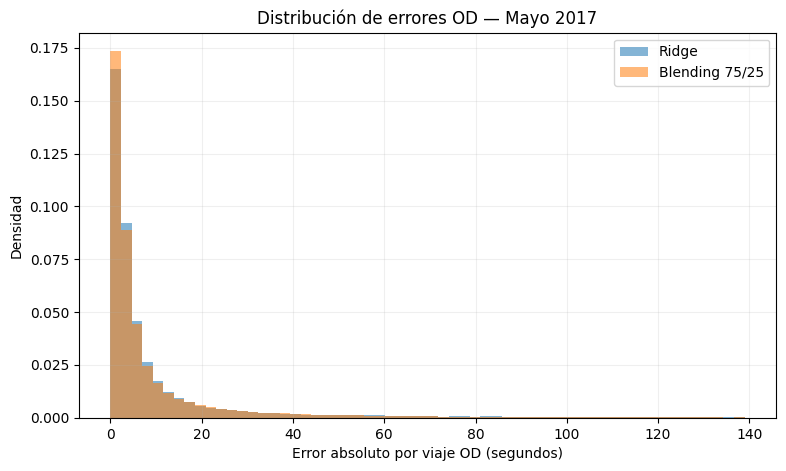

In [ ]:

# ------------------------------------------------------------
# PASO 11.3. Comparación visual de errores OD
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

limite = max(
    np.percentile(abs_ridge, 99),
    np.percentile(abs_blend, 99)
)

plt.hist(abs_ridge, bins=60, range=(0, limite),
         alpha=0.55, label="Ridge", density=True)
plt.hist(abs_blend, bins=60, range=(0, limite),
         alpha=0.55, label="Blending 75/25", density=True)

plt.xlabel("Error absoluto por viaje OD (segundos)")
plt.ylabel("Densidad")
plt.title("Distribución de errores OD — Mayo 2017")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


### 8.2. Magnitud de las subestimaciones

Cuando un modelo subestima, su predicción indica un tiempo menor al de referencia. Este tipo de error merece atención por su posible efecto sobre el cumplimiento de ventanas de entrega.

**Resultados de mayo:** el blending subestima más viajes, pero sus subestimaciones **condicionadas a que ocurran** presentan media ligeramente menor (**13.851 vs 14.318 s**) y menor P95 (**63.570 vs 67.772 s**). Al considerar **todos** los viajes, su déficit medio es mayor: **5.771 frente a 5.332 s**, una diferencia de **0.439 s por viaje**. No se puede inferir de estas cifras un impacto operativo probado.

,Ridge,Blending 75/25
Viajes subestimados (%),37.239,41.664
Subestimación media (s),14.318,13.851
Subestimación mediana (s),3.618,3.572
P95 subestimación (s),67.772,63.570
Subestimación máxima (s),410.050,419.656
Subestimación >30 s (%),4.638,4.884
Subestimación >60 s (%),2.178,2.302
Déficit medio por viaje (s),5.332,5.771


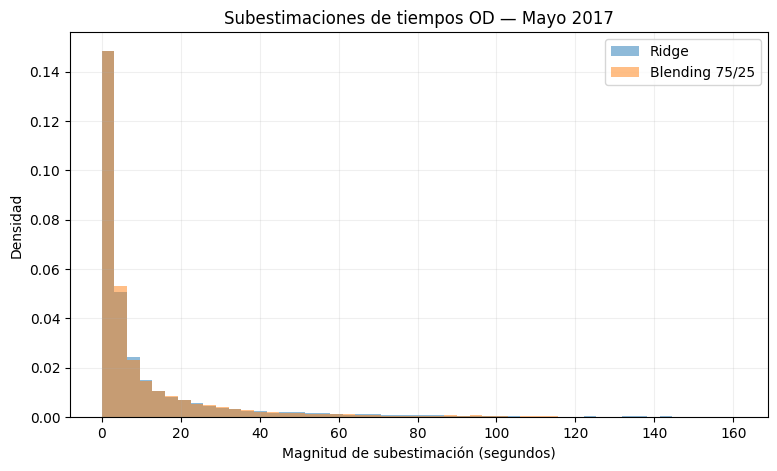

In [ ]:

# ------------------------------------------------------------
# PASO 11.4. Magnitud de las subestimaciones
# Evaluación: mayo de 2017
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def evaluar_subestimaciones(errores):
    # Error negativo = tiempo estimado menor al real
    subestimaciones = -errores[errores < 0]

    return {
        "Viajes subestimados (%)":
            100 * np.mean(errores < 0),

        "Subestimación media (s)":
            np.mean(subestimaciones),

        "Subestimación mediana (s)":
            np.median(subestimaciones),

        "P95 subestimación (s)":
            np.percentile(subestimaciones, 95),

        "Subestimación máxima (s)":
            np.max(subestimaciones),

        "Subestimación >30 s (%)":
            100 * np.mean(errores < -30),

        "Subestimación >60 s (%)":
            100 * np.mean(errores < -60),

        "Déficit medio por viaje (s)":
            np.mean(np.maximum(-errores, 0))
    }

resultados_sub = pd.DataFrame({
    "Ridge": evaluar_subestimaciones(errores_ridge),
    "Blending 75/25": evaluar_subestimaciones(errores_blend)
})

display(resultados_sub.round(3))

# Visualizar las subestimaciones
sub_ridge = -errores_ridge[errores_ridge < 0]
sub_blend = -errores_blend[errores_blend < 0]

limite = max(
    np.percentile(sub_ridge, 99),
    np.percentile(sub_blend, 99)
)

plt.figure(figsize=(9, 5))

plt.hist(
    sub_ridge,
    bins=50,
    range=(0, limite),
    density=True,
    alpha=0.5,
    label="Ridge"
)

plt.hist(
    sub_blend,
    bins=50,
    range=(0, limite),
    density=True,
    alpha=0.5,
    label="Blending 75/25"
)

plt.xlabel("Magnitud de subestimación (segundos)")
plt.ylabel("Densidad")
plt.title("Subestimaciones de tiempos OD — Mayo 2017")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


### 8.3. Intervalos de confianza exploratorios

Se organiza el error por cada uno de los **120 instantes**, emparejando las predicciones OD de ambos modelos, y se calcula un intervalo bootstrap de la diferencia media. El blending obtiene menor MAE en **73.33% de los instantes**.

- **Reducción media del MAE a favor del blending:** **0.2407 s**, IC exploratorio 95% **[−0.0395, 0.5187] s**. El intervalo **incluye cero**; no permite afirmar una mejora media estadísticamente concluyente.
- **Aumento del déficit medio por viaje del blending:** **0.4390 s**, IC exploratorio 95% **[0.0211, 0.8535] s**. En este cálculo, el intervalo queda por encima de cero.

**Precauciones:** los 120 instantes se obtuvieron mediante una muestra espaciada del mes y no forman necesariamente una secuencia continua. Por ello, el bootstrap circular con bloques de cuatro posiciones **no garantiza preservar adecuadamente la dependencia temporal real**. Sus intervalos son diagnósticos exploratorios, no pruebas confirmatorias; mayo también se consultó durante el desarrollo. Se requerirían periodos independientes y remuestreo temporal apropiado para conclusiones robustas.

In [ ]:

# ------------------------------------------------------------
# PASO 11.5. Intervalos de confianza por bloques temporales
# Ridge vs Blending 75/25 — Mayo 2017
# ------------------------------------------------------------

import numpy as np
import pandas as pd

# Los errores se almacenaron por grupo:
# 2 grupos, 120 instantes, 380 viajes por grupo
N_GRUPOS = 2
N_TIEMPOS = 120
N_OD = 380

def organizar_por_instante(errores):
    return (
        np.asarray(errores)
        .reshape(N_GRUPOS, N_TIEMPOS, N_OD)
        .transpose(1, 0, 2)
        .reshape(N_TIEMPOS, N_GRUPOS * N_OD)
    )

er = organizar_por_instante(errores_ridge)
eb = organizar_por_instante(errores_blend)

# Diferencias positivas favorecen al blending
dif_mae = np.mean(np.abs(er), axis=1) - np.mean(np.abs(eb), axis=1)

# Déficit medio: diferencias positivas favorecen a Ridge
dif_deficit = (
    np.mean(np.maximum(-eb, 0), axis=1)
    - np.mean(np.maximum(-er, 0), axis=1)
)

def bootstrap_bloques(datos, bloque=4, repeticiones=5000, semilla=42):
    rng = np.random.default_rng(semilla)
    n = len(datos)
    estimaciones = np.empty(repeticiones)

    for b in range(repeticiones):
        posiciones = []
        while len(posiciones) < n:
            inicio = rng.integers(0, n)
            posiciones.extend(
                (inicio + np.arange(bloque)) % n
            )
        posiciones = np.array(posiciones[:n])
        estimaciones[b] = datos[posiciones].mean()

    return np.percentile(estimaciones, [2.5, 97.5])

ic_mae = bootstrap_bloques(dif_mae)
ic_deficit = bootstrap_bloques(dif_deficit)

resumen_estadistico = pd.DataFrame([
    {
        "Indicador": "Reducción MAE por blending (s)",
        "Diferencia media": dif_mae.mean(),
        "IC 95% inferior": ic_mae[0],
        "IC 95% superior": ic_mae[1]
    },
    {
        "Indicador": "Aumento del déficit por blending (s)",
        "Diferencia media": dif_deficit.mean(),
        "IC 95% inferior": ic_deficit[0],
        "IC 95% superior": ic_deficit[1]
    }
])

display(resumen_estadistico.round(4))

print(
    "Instantes donde blending tiene menor MAE:",
    f"{100 * np.mean(dif_mae > 0):.2f}%"
)


,Indicador,Diferencia media,IC 95% inferior,IC 95% superior
0,Reducción MAE por blending (s),0.2407,-0.0395,0.5187
1,Aumento del déficit por blending (s),0.4390,0.0211,0.8535


Instantes donde blending tiene menor MAE: 73.33%


## 9. Conclusiones del componente de ensambles heterogéneos

1. **Mejor resultado por MAE:** el blending fijo **75% Ridge + 25% KNN** fue el mejor entre los ensambles heterogéneos evaluados. En abril su MAE OD fue **9.1325 s**, frente a **9.4479 s** de Ridge; en mayo obtuvo **11.2710 s**, frente a **11.5116 s** de Ridge. Son mejoras pequeñas, pero consistentes en dirección en esos dos periodos.
2. **Más complejidad no produjo necesariamente mejor precisión:** las mezclas con MLP no superaron al blending 75/25 en MAE, y la implementación inicial de stacking obtuvo peor desempeño en mayo (**14.4872 s**).
3. **El MAE por arista no sustituye el MAE OD:** la combinación 50/50 fue la mejor para aristas individuales, pero fue inferior a 75/25 para viajes completos.
4. **Compromiso entre exactitud y subestimación:** el blending reduce MAE y P95 de errores absolutos, pero subestima una mayor proporción de viajes y aumenta ligeramente el déficit medio global por viaje. La importancia operativa de estas diferencias todavía no se ha probado.
5. **Evidencia estadística limitada:** la reducción media del MAE a favor del blending no resultó concluyente en el intervalo exploratorio. No se ha demostrado que el modelo generalice a interrupciones, otros periodos independientes ni otras ciudades.

**Conclusión de esta parte del Avance 5:** se propone **Ridge + KNN 75/25 como candidato heterogéneo de referencia por MAE**, no como modelo universalmente superior ni como elección operativa definitiva. Ridge individual sigue siendo una referencia competitiva.

## 10. Limitaciones y trabajo posterior

**Para evaluar generalización:** reservar nuevos periodos y escenarios, incluyendo congestión fuerte, transiciones abruptas, pérdida de información, diferentes conjuntos de nodos y, cuando haya datos adecuados, otras redes geográficas. No volver a usar mayo o junio como si fueran pruebas completamente inéditas.

**Para el objetivo final del Proyecto Integrador:** alimentar el mismo optimizador con matrices estimadas por Ridge y por el candidato heterogéneo; comparar factibilidad, cumplimiento de ventanas de tiempo, retrasos, costos y decisiones de replaneación usando referencias comunes. Sólo entonces podrá valorarse el impacto logístico de una diferencia pequeña en MAE.